<a href="https://colab.research.google.com/github/kumarVaibhav02/Sonic_signatures/blob/main/Sonic_Signatures_group2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Install required libraries if running in a fresh environment
!pip install -q librosa matplotlib numpy scipy
import math
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks
import IPython.display as ipd

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.lower().endswith(('.mp3', '.mpeg', '.wav', '.m4a', '.flac')):
            print(os.path.join(root, file))

/content/drive/MyDrive/Alan Walker - Alone.mpeg
/content/drive/MyDrive/blindinglights.mpeg
/content/drive/MyDrive/table.mpeg



--- Processing Song 1 ---
Loaded: /content/drive/MyDrive/Alan Walker - Alone.mpeg | SR: 22050Hz | Duration: 30.00s | Samples: 661500

--- Processing Song 2 ---
Loaded: /content/drive/MyDrive/blindinglights.mpeg | SR: 22050Hz | Duration: 30.00s | Samples: 661500

--- Processing Song 3 ---
Loaded: /content/drive/MyDrive/table.mpeg | SR: 22050Hz | Duration: 30.00s | Samples: 661500


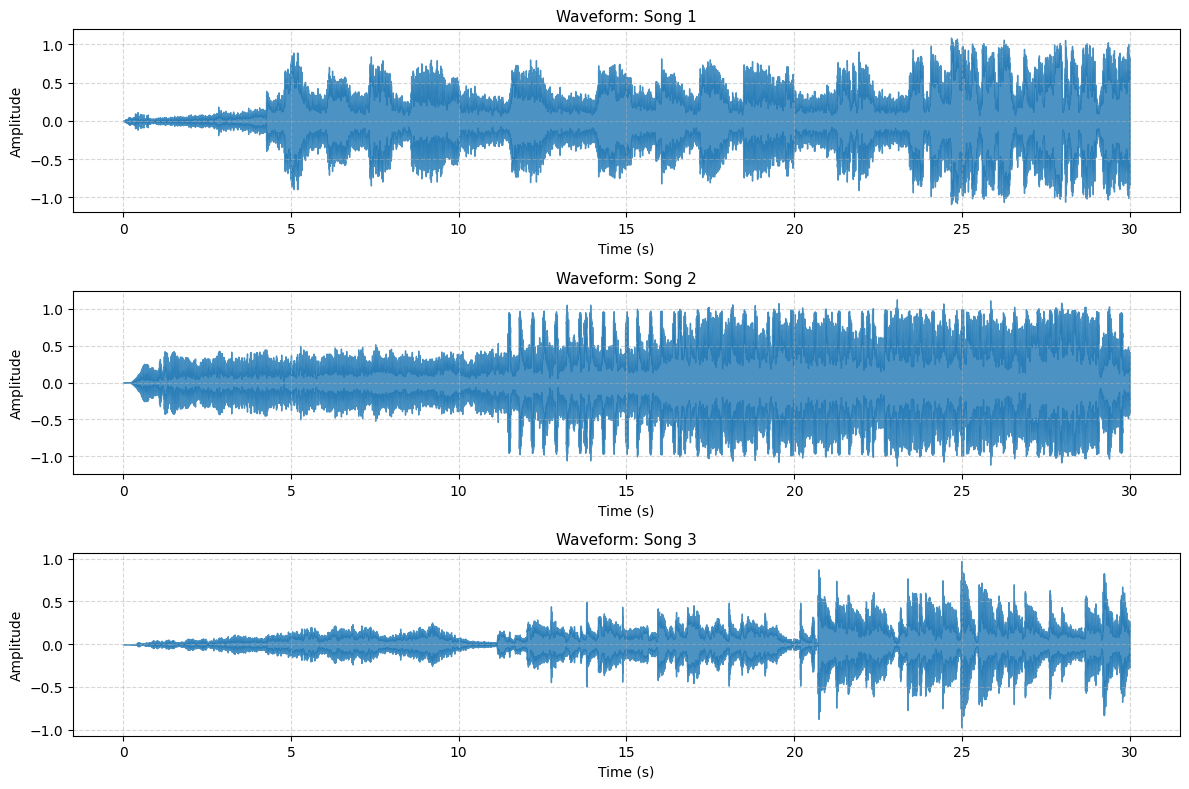

In [4]:
def load_and_standardize_audio(file_path, target_sr=22050):
    """
    Loads an audio file, converts it to mono, and resamples to target sample rate.
    """
    y, sr = librosa.load(file_path, sr=target_sr, mono=True)
    duration = librosa.get_duration(y=y, sr=sr)
    print(f"Loaded: {file_path} | SR: {sr}Hz | Duration: {duration:.2f}s | Samples: {len(y)}")
    return y, sr

# paths leading to song files
song_paths = [
   r'/content/drive/MyDrive/Alan Walker - Alone.mpeg',  # Song 1 placeholder
     r'/content/drive/MyDrive/blindinglights.mpeg', # Song 2 placeholder
    r'/content/drive/MyDrive/table.mpeg'  # Song 3 placeholder
]

# Loads all three songs
songs_data = {}
for i, path in enumerate(song_paths, start=1):
    print(f"\n--- Processing Song {i} ---")
    y, sr = load_and_standardize_audio(path)
    songs_data[f"Song {i}"] = {"y": y, "sr": sr}

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=False)
for i, (name, data) in enumerate(songs_data.items()):
    librosa.display.waveshow(data["y"], sr=data["sr"], ax=axes[i], alpha=0.8, color='tab:blue')
    axes[i].set_title(f"Waveform: {name}", fontsize=11)
    axes[i].set_xlabel("Time (s)")
    axes[i].set_ylabel("Amplitude")
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


--- Peak Detection Metrics [Song 1] ---
Total Duration : 30.00 seconds
Total Peaks    : 2011
Peak Density   : 67.03 peaks/second (Target: < 50)


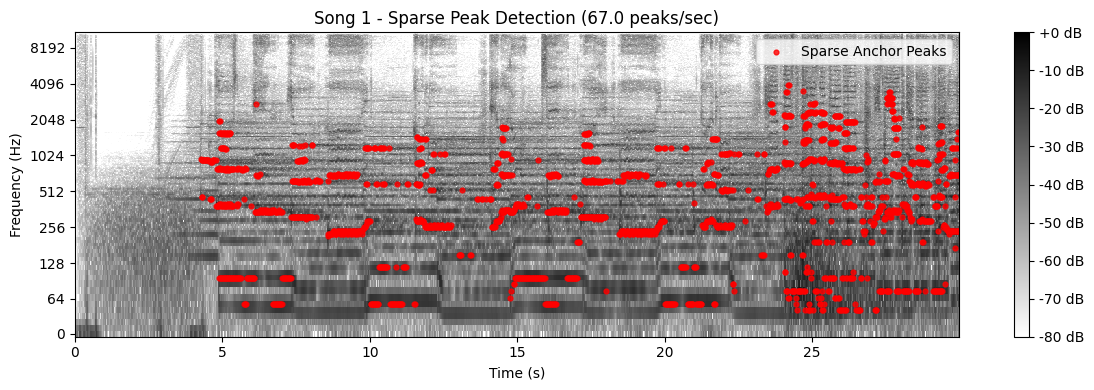


--- Peak Detection Metrics [Song 2] ---
Total Duration : 30.00 seconds
Total Peaks    : 1552
Peak Density   : 51.73 peaks/second (Target: < 50)


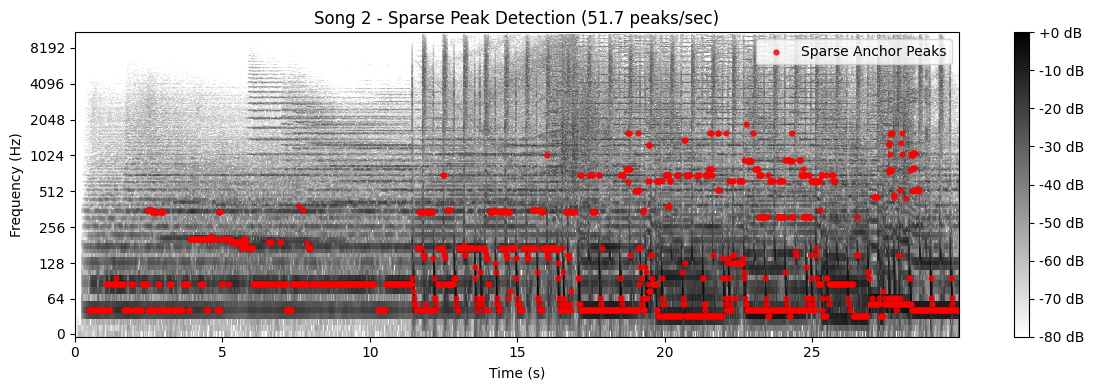


--- Peak Detection Metrics [Song 3] ---
Total Duration : 30.00 seconds
Total Peaks    : 939
Peak Density   : 31.30 peaks/second (Target: < 50)


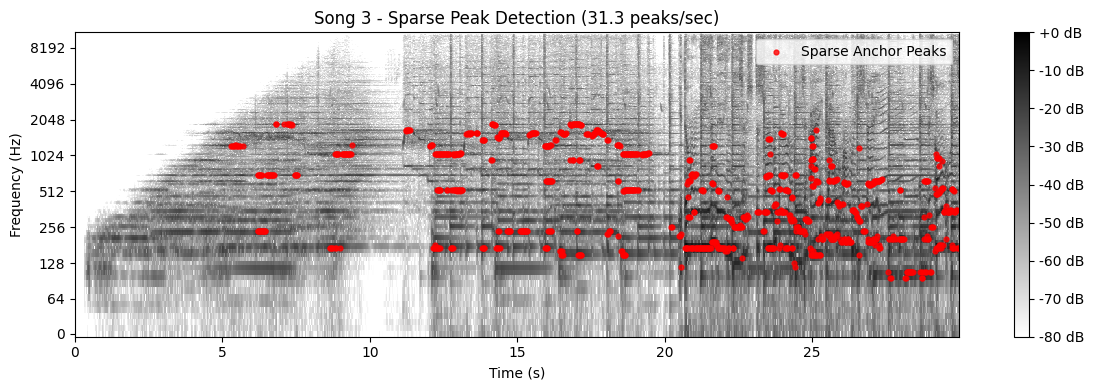

In [5]:
def detect_sparse_peaks(y, sr, track_name, n_fft=2048, hop_length=512, height_thresh=-18, distance=25):
    """
    Detects sparse local maxima to maintain < 50 prominent peaks per second,
    ideal for constellation mapping.
    """
    D = librosa.stft(y, n_fft=n_fft, hop_length=hop_length)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    peak_times = []
    peak_freqs = []
    duration = librosa.get_duration(y=y, sr=sr)

    # column-by-column peak extraction with constraints
    for t_idx in range(S_db.shape[1]):
        column = S_db[:, t_idx]
        peaks, _ = find_peaks(column, height=height_thresh, distance=distance)
        for p in peaks:
            peak_times.append(t_idx * hop_length / sr)
            peak_freqs.append(p * sr / n_fft)

    total_peaks = len(peak_times)
    peak_density = total_peaks / duration if duration > 0 else 0

    print(f"\n--- Peak Detection Metrics [{track_name}] ---")
    print(f"Total Duration : {duration:.2f} seconds")
    print(f"Total Peaks    : {total_peaks}")
    print(f"Peak Density   : {peak_density:.2f} peaks/second (Target: < 50)")

    # visualization
    plt.figure(figsize=(12, 4))
    librosa.display.specshow(S_db, sr=sr, hop_length=hop_length, x_axis='time', y_axis='log', cmap='gray_r')
    plt.colorbar(format='%+2.0f dB')

    plt.scatter(peak_times, peak_freqs, color='red', s=12, alpha=0.8, label='Sparse Anchor Peaks')
    plt.title(f"{track_name} - Sparse Peak Detection ({peak_density:.1f} peaks/sec)", fontsize=12)
    plt.xlabel("Time (s)", fontsize=10)
    plt.ylabel("Frequency (Hz)", fontsize=10)
    plt.legend(loc='upper right')
    plt.tight_layout()
    plt.show()

# run the sparse peak detector across all three songs
for name, data in songs_data.items():
    detect_sparse_peaks(
        y=data["y"],
        sr=data["sr"],
        track_name=name,
        n_fft=2048,
        hop_length=512,
        height_thresh=-18,  # filter out background noise/clutter
        distance=25         # keep peaks well-spaced out
    )


Generating spectrogram comparisons for Song 1...


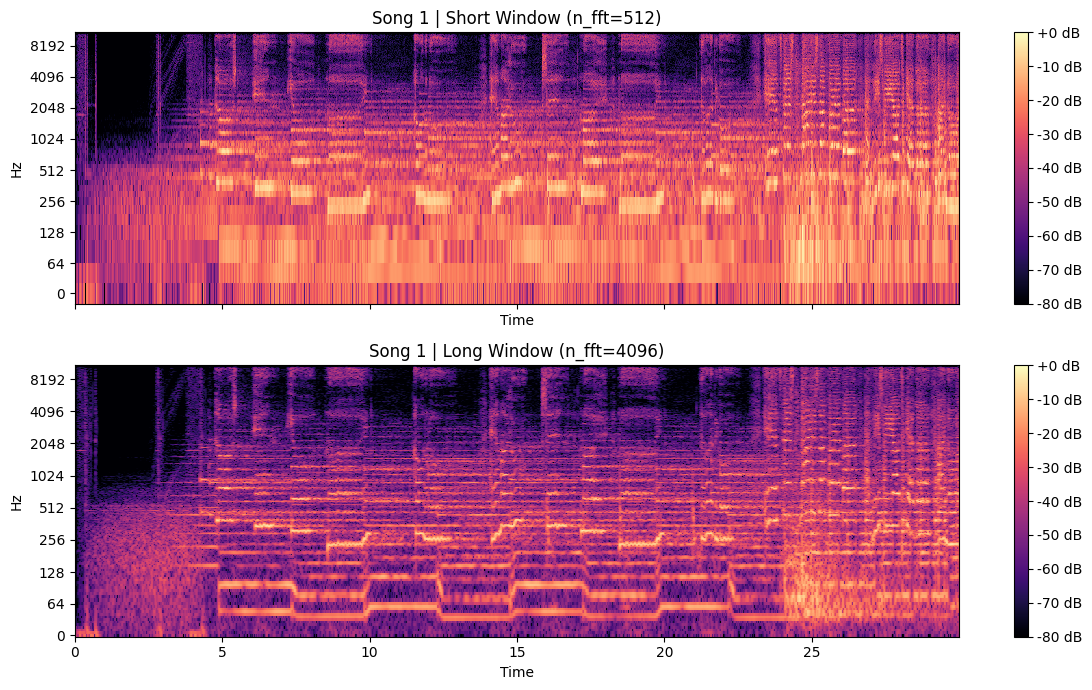


Generating spectrogram comparisons for Song 2...


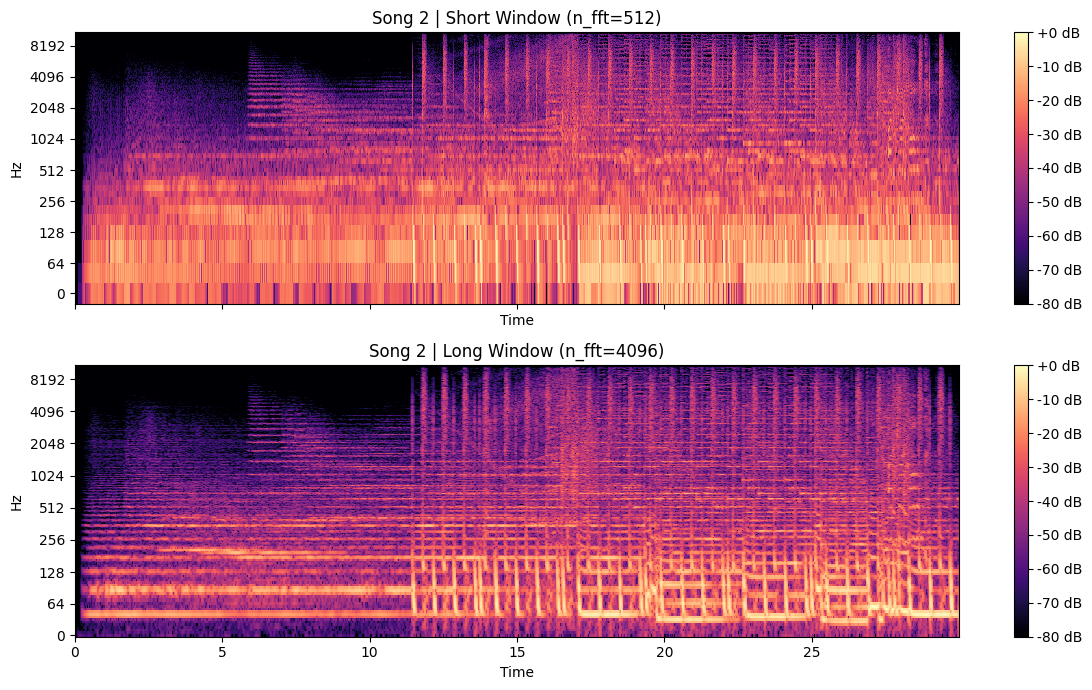


Generating spectrogram comparisons for Song 3...


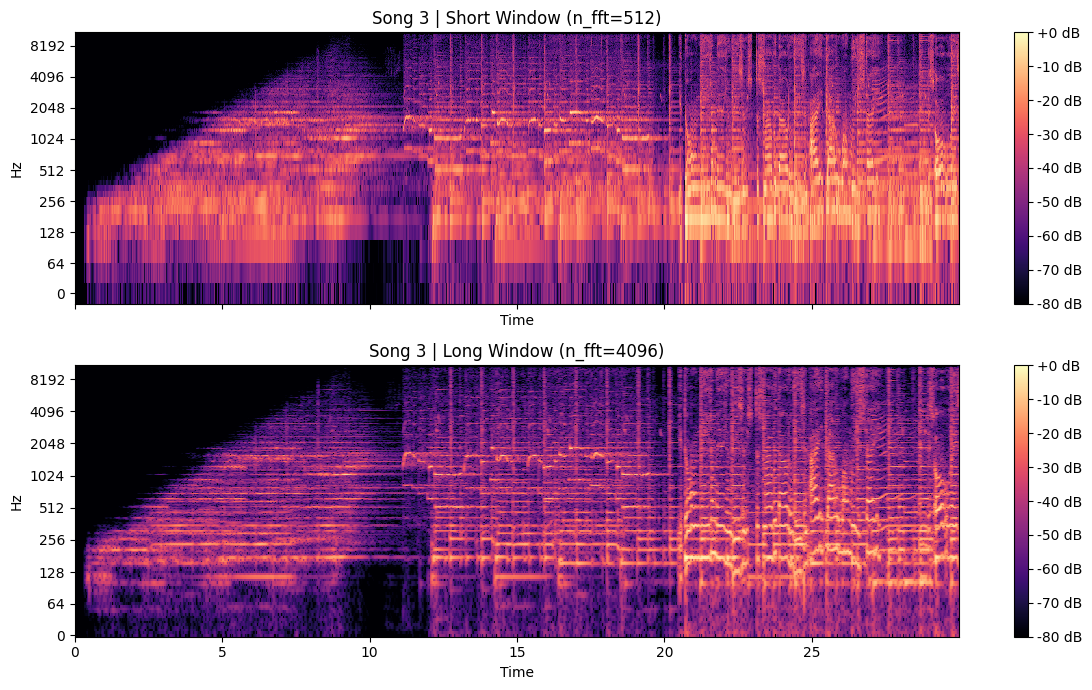

In [6]:
def compare_windows_for_song(y, sr, title):
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

    # short window (high time resolution, blurry frequencies)
    n_short = 512
    hop_short = 128
    D_short = librosa.stft(y, n_fft=n_short, hop_length=hop_short)
    S_short = librosa.amplitude_to_db(np.abs(D_short), ref=np.max)

    im1 = librosa.display.specshow(S_short, sr=sr, hop_length=hop_short, x_axis='time', y_axis='log', ax=axes[0], cmap='magma')
    axes[0].set_title(f"{title} | Short Window (n_fft={n_short})")
    fig.colorbar(im1, ax=axes[0], format='%+2.0f dB')

    # long window (high frequency resolution, smeared timing)
    n_long = 4096
    hop_long = 512
    D_long = librosa.stft(y, n_fft=n_long, hop_length=hop_long)
    S_long = librosa.amplitude_to_db(np.abs(D_long), ref=np.max)

    im2 = librosa.display.specshow(S_long, sr=sr, hop_length=hop_long, x_axis='time', y_axis='log', ax=axes[1], cmap='magma')
    axes[1].set_title(f"{title} | Long Window (n_fft={n_long})")
    fig.colorbar(im2, ax=axes[1], format='%+2.0f dB')

    plt.tight_layout()
    plt.show()

# run spectrogram comparison for each song
for name, data in songs_data.items():
    print(f"\nGenerating spectrogram comparisons for {name}...")
    compare_windows_for_song(data["y"], data["sr"], name)

### Trade-off Between Time and Frequency Resolution

When computing the Short-Time Fourier Transform (STFT) for audio fingerprinting, we face a fundamental mathematical constraint dictated by the **Heisenberg-Gabor Uncertainty Principle**: we cannot simultaneously achieve infinite precision in both time and frequency.

1. **Short Window Size (e.g., $N_{\text{fft}} = 512$):**
   * **Time Resolution:** **High.** Because the analysis window is very narrow in time (~23 ms at 22.05 kHz), transient sounds like drum beats, percussion hits, and sharp note attacks are sharply localized on the time axis.
   * **Frequency Resolution:** **Poor.** A short window contains fewer sample points, resulting in wide frequency bins. Closely spaced harmonic frequencies blur together vertically.

2. **Long Window Size (e.g., $N_{\text{fft}} = 4096$):**
   * **Frequency Resolution:** **High.** A wider window (~185 ms) captures more cycles of low-frequency waves, enabling precise pitch separation and clear horizontal harmonic bands.
   * **Time Resolution:** **Poor.** Rapid acoustic events get "smeared" or averaged out across the longer time window, making it difficult to pinpoint the exact millisecond a note started.

---

### Recommended Configuration for Shazam-Style Fingerprinting

* **Recommended Window Size ($N_{\text{fft}}$):** **`2048`** (with a `hop_length` of `512` or `256`).
* **Why:** Audio fingerprinting requires a balanced compromise. $N_{\text{fft}} = 2048$ (~92 ms window) provides sufficient frequency separation to distinguish distinct musical notes and chords while maintaining enough temporal accuracy to align song clips against a database without severe time-smearing.

In [7]:

# Extract peaks
def get_peaks(y, sr):

    D = librosa.stft(y, n_fft=2048, hop_length=512)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

    peaks_list = []

    for t_idx in range(S_db.shape[1]):

        column = S_db[:, t_idx]

        peak_indices, _ = find_peaks(
            column,
            height=-18,
            distance=25
        )

        for p in peak_indices:

            time = t_idx * 512 / sr
            frequency = p * sr / 2048
            strength = column[p]

            peaks_list.append((time, frequency, strength))

    return peaks_list


# Create the dictionary expected by Tasks 4, 5 and 6
songs = {}

for song_name, data in songs_data.items():

    songs[song_name] = get_peaks(
        data["y"],
        data["sr"]
    )

print("Peaks extracted for all songs.")

for song_name, peaks in songs.items():
    print(song_name, ":", len(peaks), "peaks")
    print("First 5 peaks:", peaks[:5])

Peaks extracted for all songs.
Song 1 : 2011 peaks
First 5 peaks: [(4.272471655328798, np.float64(958.2275390625), np.float32(-15.744324)), (4.295691609977324, np.float64(462.9638671875), np.float32(-17.532429)), (4.295691609977324, np.float64(936.6943359375), np.float32(-13.795776)), (4.31891156462585, np.float64(462.9638671875), np.float32(-16.416199)), (4.31891156462585, np.float64(936.6943359375), np.float32(-12.825722))]
Song 2 : 1552 peaks
First 5 peaks: [(0.46439909297052157, np.float64(43.06640625), np.float32(-17.545284)), (0.4876190476190476, np.float64(43.06640625), np.float32(-16.615147)), (0.5108390022675737, np.float64(43.06640625), np.float32(-15.971905)), (0.5340589569160997, np.float64(43.06640625), np.float32(-15.605656)), (0.5572789115646258, np.float64(43.06640625), np.float32(-15.448044))]
Song 3 : 939 peaks
First 5 peaks: [(5.294149659863946, np.float64(1238.1591796875), np.float32(-17.943161)), (5.317369614512471, np.float64(1238.1591796875), np.float32(-15.73543

In [13]:
# TASK 4(making fingerprints)
def create_peak_pairs(peaks, max_time_gap=0.5):
    fingerprints = []

    # Choose each peak as the first peak
    for i in range(len(peaks)):

        time1, freq1, strength1 = peaks[i]

        # Search for a second peak after the first peak
        for j in range(i + 1, len(peaks)):

            time2, freq2, strength2 = peaks[j]

            time_gap = time2 - time1

            # Ignore pairs that are too far apart in time
            if time_gap > max_time_gap:
                break

            # Store the two frequencies and their time separation
            fingerprint = (
                freq1,
                freq2,
                round(time_gap, 3)
            )

            fingerprints.append(fingerprint)

    return fingerprints


def show_fingerprints(song_data):
    all_fingerprints = {}

    for song_name, peaks in song_data.items():
        fingerprints = create_peak_pairs(peaks)

        all_fingerprints[song_name] = fingerprints

        print("\n", song_name)
        print("Number of fingerprints:", len(fingerprints))
        print("First five fingerprints:")
        for freq1, freq2, time_gap in fingerprints[:5]:
            print(
                f"Frequency 1: {float(freq1):.0f} Hz, "
                f"Frequency 2: {float(freq2):.0f} Hz, "
                f"Time gap: {float(time_gap):.3f} s"
            )

    return all_fingerprints


# Generate fingerprints for every reference song
fingerprints = show_fingerprints(songs)



 Song 1
Number of fingerprints: 93878
First five fingerprints:
Frequency 1: 958 Hz, Frequency 2: 463 Hz, Time gap: 0.023 s
Frequency 1: 958 Hz, Frequency 2: 937 Hz, Time gap: 0.023 s
Frequency 1: 958 Hz, Frequency 2: 463 Hz, Time gap: 0.046 s
Frequency 1: 958 Hz, Frequency 2: 937 Hz, Time gap: 0.046 s
Frequency 1: 958 Hz, Frequency 2: 937 Hz, Time gap: 0.070 s

 Song 2
Number of fingerprints: 41913
First five fingerprints:
Frequency 1: 43 Hz, Frequency 2: 43 Hz, Time gap: 0.023 s
Frequency 1: 43 Hz, Frequency 2: 43 Hz, Time gap: 0.046 s
Frequency 1: 43 Hz, Frequency 2: 43 Hz, Time gap: 0.070 s
Frequency 1: 43 Hz, Frequency 2: 43 Hz, Time gap: 0.093 s
Frequency 1: 43 Hz, Frequency 2: 43 Hz, Time gap: 0.116 s

 Song 3
Number of fingerprints: 22704
First five fingerprints:
Frequency 1: 1238 Hz, Frequency 2: 1238 Hz, Time gap: 0.023 s
Frequency 1: 1238 Hz, Frequency 2: 1238 Hz, Time gap: 0.093 s
Frequency 1: 1238 Hz, Frequency 2: 1238 Hz, Time gap: 0.116 s
Frequency 1: 1238 Hz, Frequency 

In [16]:
# ============================================================
# TASK 5: BASELINE SPECTRAL MATCHING
# ============================================================

def calculate_spectral_features(peaks, frequency_bins):
    features = []

    for low_freq, high_freq in frequency_bins:

        strengths = []

        # Collect strengths of peaks inside this frequency range
        for time, frequency, strength in peaks:
            if low_freq <= frequency < high_freq:
                strengths.append(strength)

        # Calculate the average strength in this range
        if len(strengths) > 0:
            average = sum(strengths) / len(strengths)
        else:
            average = 0.0

        features.append(average)

    return features


def calculate_distance(features1, features2):
    total = 0

    for i in range(len(features1)):
        difference = features1[i] - features2[i]
        total += difference ** 2

    return math.sqrt(total)

def baseline_recognizer(reference_songs, query_peaks, frequency_bins):
    query_features = calculate_spectral_features(
        query_peaks, frequency_bins
    )

    scores = {}

    for song_name, peaks in reference_songs.items():
        reference_features = calculate_spectral_features(
            peaks, frequency_bins
        )

        distance = calculate_distance(
            query_features, reference_features
        )

        scores[song_name] = distance

    # The smallest distance means the most similar feature vector
    predicted_song = min(scores, key=scores.get)

    return predicted_song, scores[predicted_song], scores

# Frequency ranges
frequency_bins = [
    (0, 200),
    (200, 500),
    (500, 1000),
    (1000, 2000),
    (2000, 4000)
]
# For example, we are taking the first five seconds of song 1 as query audio
query_y = songs_data["Song 1"]["y"][:5 * songs_data["Song 1"]["sr"]]

query_sr = songs_data["Song 1"]["sr"]

query_peaks = get_peaks(query_y, query_sr)

predicted_song, best_distance, all_distances = baseline_recognizer(
    songs, query_peaks, frequency_bins
)

similarity_score = 1 / (1 + best_distance)
for song_name, distance in all_distances.items():
    print(f"{song_name} distance: {distance:.4f}")

print("\nTASK 5: BASELINE RECOGNITION")
print("Predicted song:", predicted_song)
print("Similarity score:", round(similarity_score * 100, 2), "%")


Song 1 distance: 15.5597
Song 2 distance: 9.0189
Song 3 distance: 5.1077

TASK 5: BASELINE RECOGNITION
Predicted song: Song 3
Similarity score: 16.37 %



TASK 6: SHAZAM-STYLE RECOGNITION
Predicted song: Song 1
Estimated query offset: 0.0 seconds
Offset votes: {('Song 1', 0.51): 108, ('Song 1', 0.53): 67, ('Song 1', 9.59): 1, ('Song 1', 9.73): 1, ('Song 1', 10.01): 9, ('Song 1', 10.03): 16, ('Song 1', 19.09): 1, ('Song 1', 19.99): 25, ('Song 1', 20.02): 34, ('Song 1', 20.04): 37, ('Song 1', 20.06): 40, ('Song 1', 20.13): 11, ('Song 1', 20.41): 12, ('Song 1', 20.43): 10, ('Song 1', 21.55): 54, ('Song 1', 21.64): 13, ('Song 1', 21.66): 13, ('Song 1', 21.69): 18, ('Song 1', 21.71): 22, ('Song 1', 21.73): 31, ('Song 1', 21.76): 27, ('Song 1', 21.78): 13, ('Song 1', 21.8): 3, ('Song 1', 21.83): 1, ('Song 1', 20.09): 24, ('Song 1', 21.57): 42, ('Song 1', 20.62): 23, ('Song 1', 20.46): 5, ('Song 1', 20.15): 8, ('Song 1', 0.49): 97, ('Song 1', 9.57): 1, ('Song 1', 9.71): 1, ('Song 1', 9.98): 9, ('Song 1', 19.06): 1, ('Song 1', 19.97): 16, ('Song 1', 20.11): 22, ('Song 1', 20.39): 7, ('Song 1', 21.52): 39, ('Song 1', 21.62): 16, ('Song 1', 20.6)

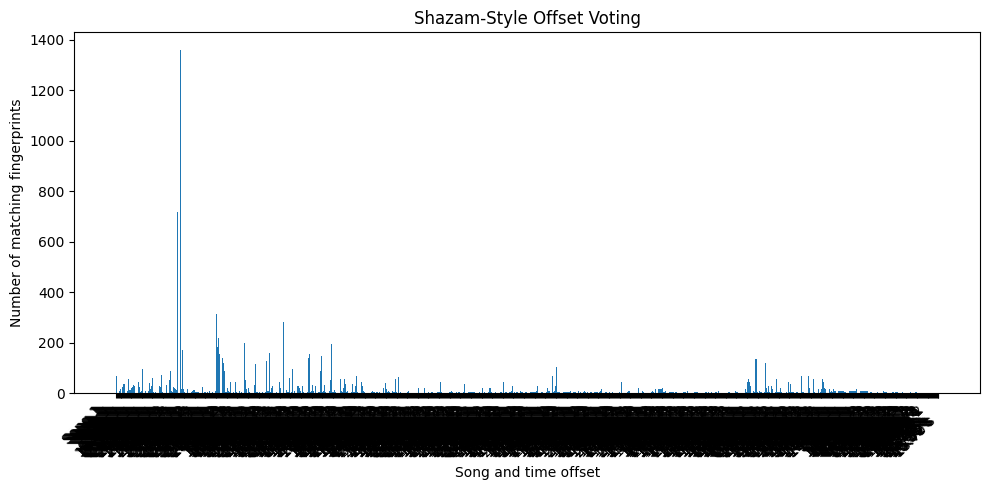

In [10]:

# ============================================================
# TASK 6: SHAZAM-STYLE PEAK-PAIR MATCHING
# ============================================================

# These settings follow Group 1's recommendation
N_FFT = 2048
HOP_LENGTH = 512
MAX_TIME_GAP = 0.5


def build_fingerprint_index(reference_songs):
    index = {}

    for song_name, peaks in reference_songs.items():

        for i in range(len(peaks)):

            time1, freq1, strength1 = peaks[i]

            for j in range(i + 1, len(peaks)):

                time2, freq2, strength2 = peaks[j]

                time_gap = time2 - time1

                if time_gap > MAX_TIME_GAP:
                    break

                fingerprint = (
                    round(freq1, 1),
                    round(freq2, 1),
                    round(time_gap, 3)
                )

                if fingerprint not in index:
                    index[fingerprint] = []

                # Store song name and anchor time
                index[fingerprint].append((song_name, time1))

    return index


def match_fingerprints(query_peaks, fingerprint_index):
    votes = {}

    query_fingerprints = []

    # Generate query fingerprints and keep their anchor times
    for i in range(len(query_peaks)):

        time1, freq1, strength1 = query_peaks[i]

        for j in range(i + 1, len(query_peaks)):

            time2, freq2, strength2 = query_peaks[j]

            time_gap = time2 - time1

            if time_gap > MAX_TIME_GAP:
                break

            fingerprint = (
                round(freq1, 1),
                round(freq2, 1),
                round(time_gap, 3)
            )

            query_fingerprints.append((fingerprint, time1))

    # Match query fingerprints against the reference index
    for fingerprint, query_time in query_fingerprints:

        if fingerprint in fingerprint_index:

            for song_name, reference_time in fingerprint_index[fingerprint]:

                # Estimate where the query starts in the reference song
                offset = round(reference_time - query_time, 2)

                key = (song_name, offset)

                if key not in votes:
                    votes[key] = 0

                votes[key] += 1

    return votes


def shazam_recognizer(reference_songs, query_peaks):

    fingerprint_index = build_fingerprint_index(reference_songs)

    votes = match_fingerprints(
        query_peaks,
        fingerprint_index
    )

    if len(votes) == 0:
        return "No match found", None, votes

    # Count matching fingerprints for each song
    song_votes = {}

    for (song_name, offset), count in votes.items():

        if song_name not in song_votes:
            song_votes[song_name] = 0

        song_votes[song_name] += count

    predicted_song = max(song_votes, key=song_votes.get)

    # Find the strongest offset for the predicted song
    best_offset = None
    best_offset_votes = -1

    for (song_name, offset), count in votes.items():

        if song_name == predicted_song and count > best_offset_votes:
            best_offset = offset
            best_offset_votes = count

    return predicted_song, best_offset, votes


# Run Task 6
predicted_song, best_offset, offset_votes = shazam_recognizer(
    songs,
    query_peaks
)

print("\nTASK 6: SHAZAM-STYLE RECOGNITION")
print("Predicted song:", predicted_song)
print("Estimated query offset:", best_offset, "seconds")
print("Offset votes:", offset_votes)


# ============================================================
# VISUALISE THE OFFSET-VOTING HISTOGRAM
# ============================================================

if len(offset_votes) > 0:

    labels = []
    counts = []

    for (song_name, offset), count in offset_votes.items():

        labels.append(song_name + "\n" + str(offset) + " s")
        counts.append(count)

    plt.figure(figsize=(10, 5))
    plt.bar(labels, counts)

    plt.xlabel("Song and time offset")
    plt.ylabel("Number of matching fingerprints")
    plt.title("Shazam-Style Offset Voting")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

else:
    print("No matching fingerprints to visualise.")
